# Notebook 09 — Exploratory Data Analysis

This notebook explores the distribution of weather, soil moisture, and light indices and evaluates their correlations with estate coconut yield.

## 1. Import Packages & Local Configuration

In [1]:
import sys
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Ensure project root is in the path
sys.path.append(str(Path(os.getcwd()).parent))

import config
print("Figures Folder:", config.FIGURES_DIR)

Figures Folder: D:\A1\coco\Coconut_Yield_Prediction\figures


## 2. Load Features Dataset

In [2]:
df = pd.read_csv(config.PROCESSED_DIR / "master_features.csv")
print("Shape:", df.shape)
print(df.describe())

Shape: (608, 37)
              Year       Month    Rainfall  Temperature    Humidity  \
count   608.000000  608.000000  608.000000   608.000000  608.000000   
mean   2021.684211    6.291118  161.486349    27.033898   82.394359   
std       1.838347    3.488147  119.675036     1.089688    4.714157   
min    2019.000000    1.000000    1.860000    24.530000   62.720000   
25%    2020.000000    3.000000   68.510000    26.335000   79.910000   
50%    2022.000000    6.000000  135.000000    26.960000   83.915000   
75%    2023.000000    9.000000  238.700000    27.690000   85.510000   
max    2025.000000   12.000000  557.380000    30.540000   89.290000   

       Soil_Moisture_Top  Soil_Moisture_Root  Soil_Moisture_Diff  \
count         608.000000          608.000000          608.000000   
mean            0.687714            0.681217           -0.006497   
std             0.135690            0.134503            0.025857   
min             0.360000            0.450000           -0.050000   
25%

## 3. Distributive Histograms

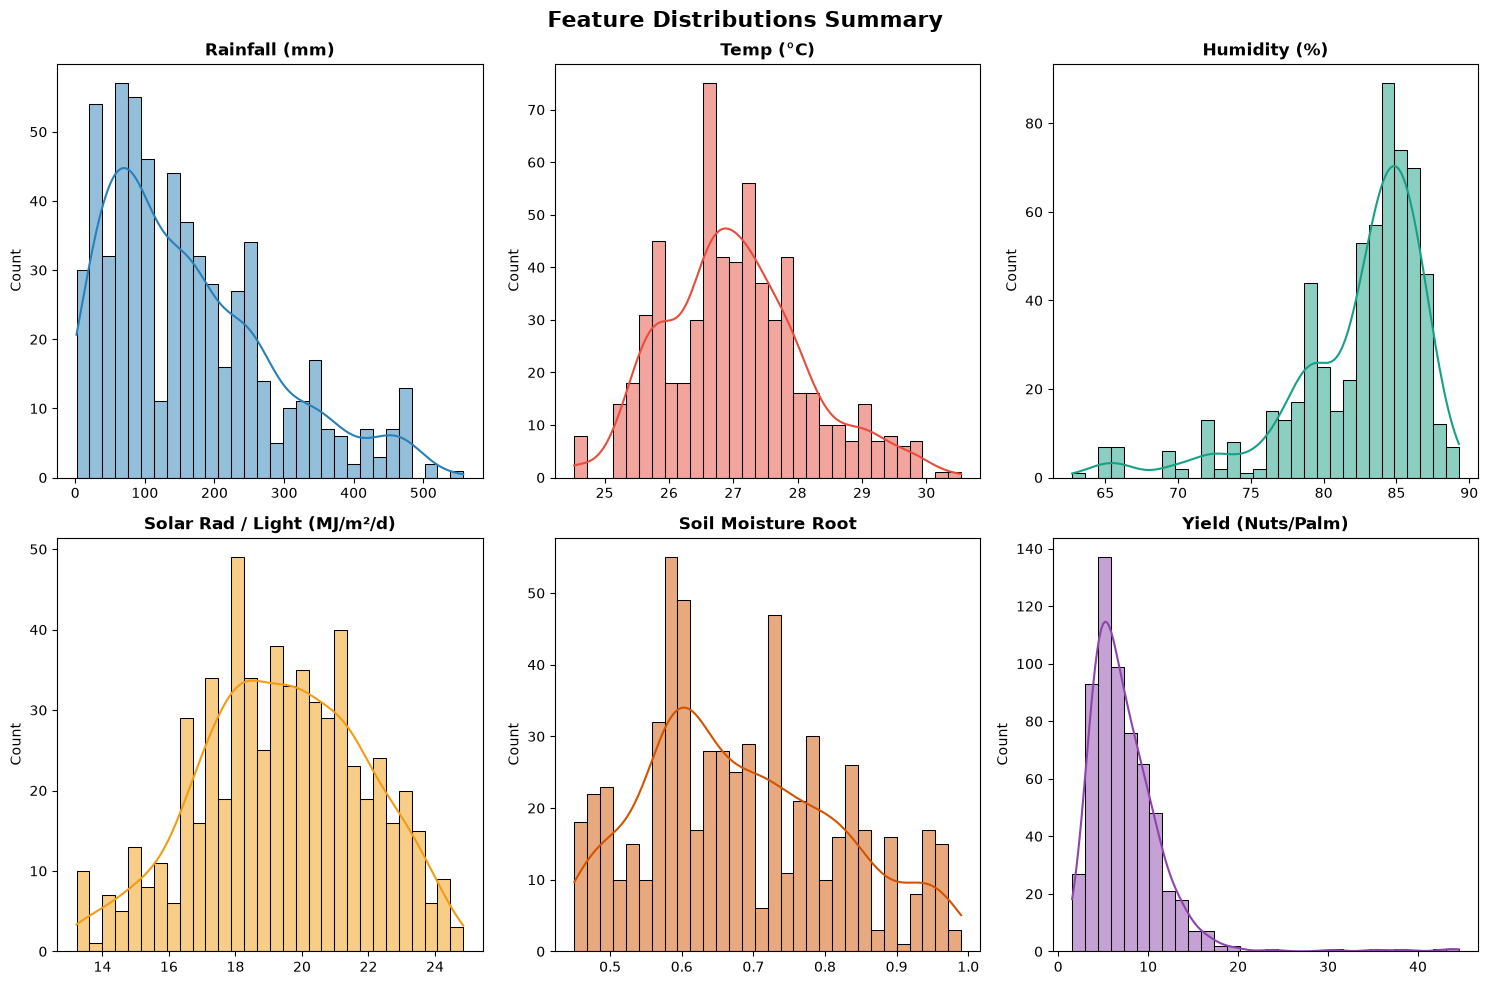

In [3]:
fig, axes = plt.subplots(2, 3, figsize=(15, 10))
metrics = ["Rainfall", "Temperature", "Humidity", "Solar_Radiation", "Soil_Moisture_Root", "Avg_Nuts_Palm"]
titles = ["Rainfall (mm)", "Temp (°C)", "Humidity (%)", "Solar Rad / Light (MJ/m²/d)", "Soil Moisture Root", "Yield (Nuts/Palm)"]
colors = ["#2980b9", "#e74c3c", "#16a085", "#f39c12", "#d35400", "#8e44ad"]

for i, ax in enumerate(axes.flat):
    sns.histplot(df[metrics[i]], bins=30, kde=True, ax=ax, color=colors[i])
    ax.set_title(titles[i], fontsize=12, fontweight='bold')
    ax.set_xlabel("")
    ax.set_ylabel("Count")

plt.suptitle("Feature Distributions Summary", fontsize=16, fontweight='bold', y=0.98)
plt.tight_layout()
plt.savefig(config.FIGURES_DIR / "feature_distributions.png", dpi=300)
plt.show()

## 4. Correlation Heatmap

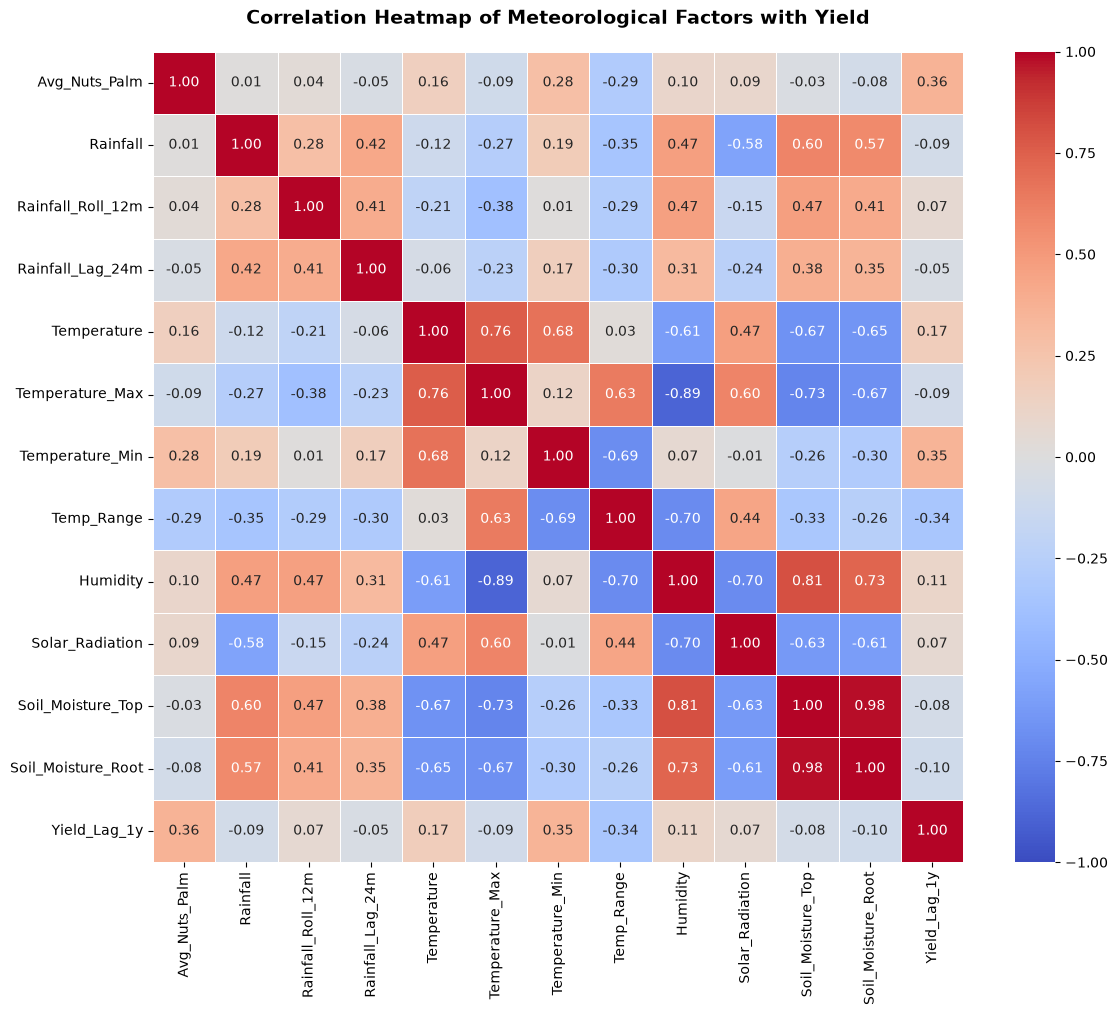

In [4]:
corr_cols = [
    "Avg_Nuts_Palm", "Rainfall", "Rainfall_Roll_12m", "Rainfall_Lag_24m",
    "Temperature", "Temperature_Max", "Temperature_Min", "Temp_Range",
    "Humidity", "Solar_Radiation", "Soil_Moisture_Top", "Soil_Moisture_Root", "Yield_Lag_1y"
]

corr_matrix = df[corr_cols].corr()

plt.figure(figsize=(12, 10))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, square=True, linewidths=0.5)
plt.title("Correlation Heatmap of Meteorological Factors with Yield", fontsize=14, fontweight='bold', pad=20)
plt.tight_layout()
plt.savefig(config.FIGURES_DIR / "correlation_heatmap.png", dpi=300)
plt.show()

## 5. Temporal Trends of Yield vs Soil Moisture & Rain

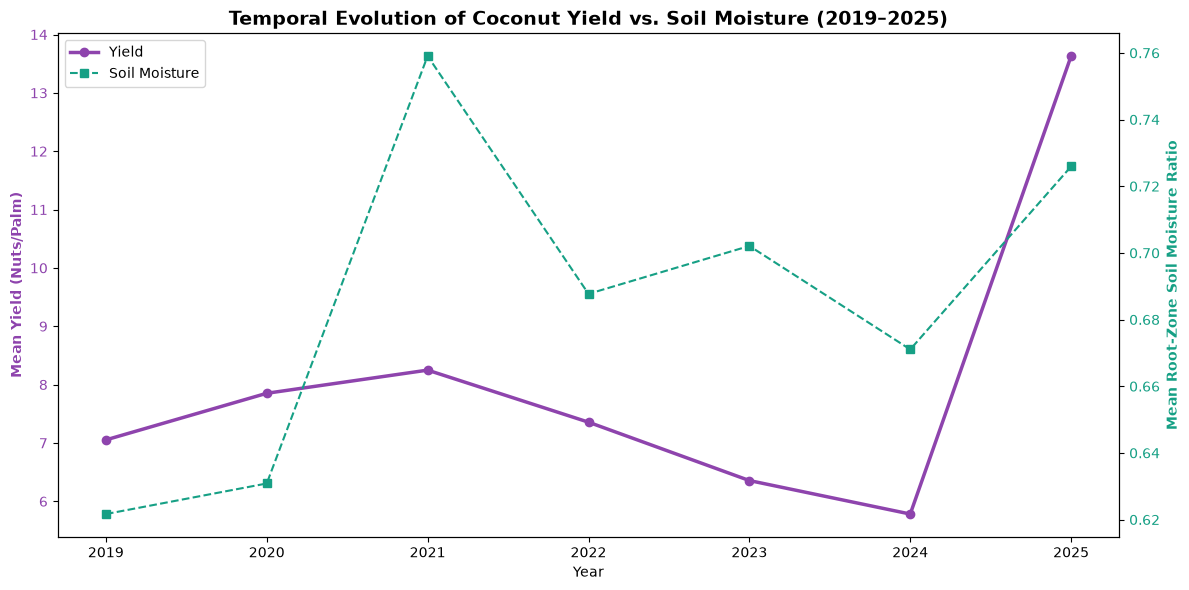

In [5]:
df_yearly = df.groupby("Year")[["Rainfall", "Soil_Moisture_Root", "Avg_Nuts_Palm"]].mean().reset_index()

fig, ax1 = plt.subplots(figsize=(12, 6))

# Left Y-axis (Yield)
color = '#8e44ad'
ax1.set_xlabel('Year')
ax1.set_ylabel('Mean Yield (Nuts/Palm)', color=color, fontweight='bold')
line1 = ax1.plot(df_yearly['Year'], df_yearly['Avg_Nuts_Palm'], color=color, marker='o', linewidth=2.5, label='Yield')
ax1.tick_params(axis='y', labelcolor=color)

# Right Y-axis (Soil Moisture)
ax2 = ax1.twinx()
color = '#16a085'
ax2.set_ylabel('Mean Root-Zone Soil Moisture Ratio', color=color, fontweight='bold')
line2 = ax2.plot(df_yearly['Year'], df_yearly['Soil_Moisture_Root'], color=color, marker='s', linestyle='--', linewidth=1.5, label='Soil Moisture')
ax2.tick_params(axis='y', labelcolor=color)

lines = line1 + line2
labels = [l.get_label() for l in lines]
ax1.legend(lines, labels, loc='upper left')

plt.title("Temporal Evolution of Coconut Yield vs. Soil Moisture (2019–2025)", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(config.FIGURES_DIR / "yield_moisture_trends.png", dpi=300)
plt.show()